In [25]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pyspark.sql import SparkSession

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

In [36]:
spark = SparkSession.builder \
    .appName("Velib_Model_Training") \
    .getOrCreate()

# Read the processed data
OUTPUT_PATH = "hdfs://localhost:9000/user/hadoop/data/data_with_meteo_final"
spark_df = spark.read.parquet(OUTPUT_PATH)

# Show schema and sample data
spark_df.printSchema()
spark_df.show(5)

root
 |-- stationcode: string (nullable = true)
 |-- name: string (nullable = true)
 |-- is_installed: string (nullable = true)
 |-- capacity: long (nullable = true)
 |-- numdocksavailable: long (nullable = true)
 |-- numbikesavailable: long (nullable = true)
 |-- mechanical: long (nullable = true)
 |-- ebike: long (nullable = true)
 |-- is_renting: string (nullable = true)
 |-- is_returning: string (nullable = true)
 |-- duedate: timestamp (nullable = true)
 |-- coordonnees_geo: struct (nullable = true)
 |    |-- lat: double (nullable = true)
 |    |-- lon: double (nullable = true)
 |-- nom_arrondissement_communes: string (nullable = true)
 |-- code_insee_commune: string (nullable = true)
 |-- temperature_2m: double (nullable = true)
 |-- precipitation: double (nullable = true)
 |-- rain: double (nullable = true)
 |-- snowfall: double (nullable = true)
 |-- relative_humidity_2m: double (nullable = true)
 |-- is_holiday: integer (nullable = true)
 |-- hour: integer (nullable = true)
 |

In [37]:
df = spark_df.toPandas()

df

,stationcode,name,is_installed,capacity,numdocksavailable,numbikesavailable,mechanical,ebike,is_renting,is_returning,duedate,coordonnees_geo,nom_arrondissement_communes,code_insee_commune,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,is_holiday,hour,month,dayofweek,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,bikes_ratio,docks_ratio,is_raining
0,16107,Benjamin Godard - Victor Hugo,OUI,35.0,30,4,2,2,OUI,OUI,2025-12-17 06:26:32,"(48.865983, 2.275725)",Paris,75056,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.000000,6.123234e-17,0.433884,-0.900969,0.114286,0.857143,0
1,40001,Hôpital Mondor,OUI,28.0,12,17,2,15,OUI,OUI,2025-12-17 06:33:29,"(48.798922410229, 2.4537451531298)",Créteil,94028,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.000000,6.123234e-17,0.433884,-0.900969,0.607143,0.428571,0
2,32304,Charcot - Benfleet,OUI,28.0,22,4,2,2,OUI,OUI,2025-12-17 06:28:10,"(48.878370277021, 2.440523876268)",Romainville,93063,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.000000,6.123234e-17,0.433884,-0.900969,0.142857,0.785714,0
3,11104,Charonne - Robert et Sonia Delaunay,OUI,20.0,12,8,1,7,OUI,OUI,2025-12-17 06:32:00,"(48.855907555969, 2.3925706744194)",Paris,75056,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.000000,6.123234e-17,0.433884,-0.900969,0.400000,0.600000,0
4,8026,Messine - Place Du Pérou,OUI,12.0,7,4,4,0,OUI,OUI,2025-12-17 06:33:20,"(48.875448033960744, 2.315508019010038)",Paris,75056,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.000000,6.123234e-17,0.433884,-0.900969,0.333333,0.583333,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179165,13101,Croulebarde - Corvisart,OUI,34.0,21,13,10,3,OUI,OUI,2024-11-01 08:49:34,"(48.830981659316855, 2.3481646925210953)",Paris,75056,9.5,0.0,0.0,0.0,98.333244,1,8,11,5,1,0.866025,-5.000000e-01,-0.974928,-0.222521,0.382353,0.617647,0
179166,17025,Chazelles - Courcelles,OUI,35.0,29,4,2,2,OUI,OUI,2024-11-01 08:47:23,"(48.879406604954, 2.3034455627202988)",Paris,75056,9.5,0.0,0.0,0.0,98.333244,1,8,11,5,1,0.866025,-5.000000e-01,-0.974928,-0.222521,0.114286,0.828571,0
179167,20143,Ramponeau - Belleville,OUI,44.0,30,13,2,11,OUI,OUI,2024-11-01 08:49:34,"(48.871031137596, 2.379056852114)",Paris,75056,9.5,0.0,0.0,0.0,98.333244,1,8,11,5,1,0.866025,-5.000000e-01,-0.974928,-0.222521,0.295455,0.681818,0
179168,16138,Saint-Cloud - Hippodrome,OUI,30.0,26,3,3,0,OUI,OUI,2024-11-01 08:43:11,"(48.85772148887421, 2.2549109905958176)",Paris,75056,9.5,0.0,0.0,0.0,98.333244,1,8,11,5,1,0.866025,-5.000000e-01,-0.974928,-0.222521,0.100000,0.866667,0


In [38]:
df.describe()

,capacity,numdocksavailable,numbikesavailable,mechanical,ebike,duedate,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,is_holiday,hour,month,dayofweek,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,bikes_ratio,docks_ratio,is_raining
count,179169.000000,179170.000000,179170.000000,179170.000000,179170.000000,179170,177406.000000,177406.000000,177406.000000,177406.000000,177406.000000,179170.000000,179170.000000,179170.000000,179170.000000,179170.000000,179170.000000,1.791700e+05,179170.000000,179170.000000,179169.000000,179169.000000,179170.000000
mean,31.930049,18.609511,12.408818,7.717732,4.691087,2025-11-13 00:43:30.170871296,8.712159,0.078403,0.077715,0.000481,92.104221,0.480627,12.184785,11.879907,2.857398,0.287833,-0.072374,-2.173973e-02,0.167864,0.111250,0.385580,0.579696,0.142769
min,1.000000,0.000000,0.000000,0.000000,0.000000,2018-03-16 16:30:20,-2.450000,0.000000,0.000000,0.000000,50.799690,0.000000,0.000000,2.000000,0.000000,0.000000,-1.000000,-1.000000e+00,-0.974928,-0.900969,0.000000,0.000000,0.000000
25%,23.000000,9.000000,4.000000,1.000000,2.000000,2025-12-16 07:25:07.249999872,7.750000,0.000000,0.000000,0.000000,88.041320,0.000000,6.000000,12.000000,1.000000,0.000000,-0.707107,-7.071068e-01,-0.781831,-0.222521,0.142857,0.360000,0.000000
50%,30.000000,17.000000,9.000000,4.000000,3.000000,2025-12-17 13:33:45,9.000000,0.000000,0.000000,0.000000,92.748660,0.000000,12.000000,12.000000,2.000000,0.000000,0.000000,6.123234e-17,0.433884,-0.222521,0.325000,0.636364,0.000000
75%,38.000000,26.000000,18.000000,11.000000,6.000000,2025-12-20 16:44:01,10.000000,0.000000,0.000000,0.000000,97.346030,1.000000,18.000000,12.000000,5.000000,1.000000,0.707107,7.071068e-01,0.974928,0.623490,0.600000,0.826087,0.000000
max,105.000000,100.000000,83.000000,73.000000,48.000000,2025-12-23 16:53:23,20.750000,4.500000,4.500000,1.260000,100.000000,1.000000,23.000000,12.000000,6.000000,1.000000,1.000000,1.000000e+00,0.974928,1.000000,1.800000,1.000000,1.000000
std,12.691594,12.394096,10.978787,9.495081,4.364722,NaN,2.177765,0.346525,0.345222,0.019798,5.992823,0.499626,6.823831,0.595313,2.070285,0.452754,0.701845,7.083137e-01,0.724972,0.658685,0.283054,0.287939,0.349839


In [39]:
if 'duedate' in df.columns:
    df['duedate'] = pd.to_datetime(df['duedate'])
    df = df.sort_values(by='duedate').reset_index(drop=True)

print("--- FORME DES DONNÉES ---")
print(f"Dimensions : {df.shape}")
print(f"Types :\n{df.dtypes.value_counts()}")

--- FORME DES DONNÉES ---
Dimensions : (179170, 31)
Types :
float64           12
object             8
int32              6
int64              4
datetime64[ns]     1
Name: count, dtype: int64



--- VALEURS MANQUANTES ---
name                              1
capacity                          1
coordonnees_geo                   1
nom_arrondissement_communes       1
code_insee_commune                1
temperature_2m                 1764
precipitation                  1764
rain                           1764
snowfall                       1764
relative_humidity_2m           1764
bikes_ratio                       1
docks_ratio                       1
dtype: int64


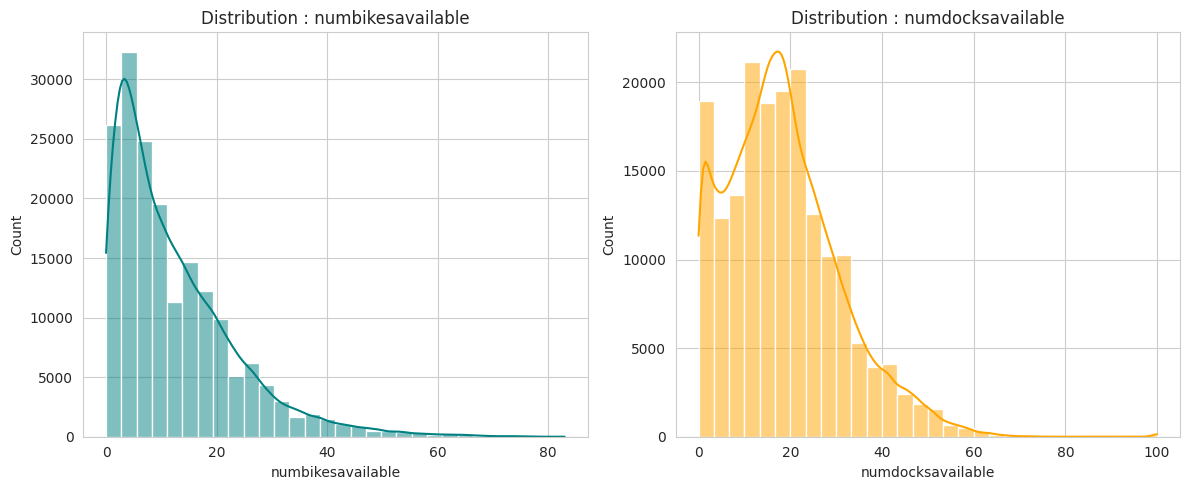

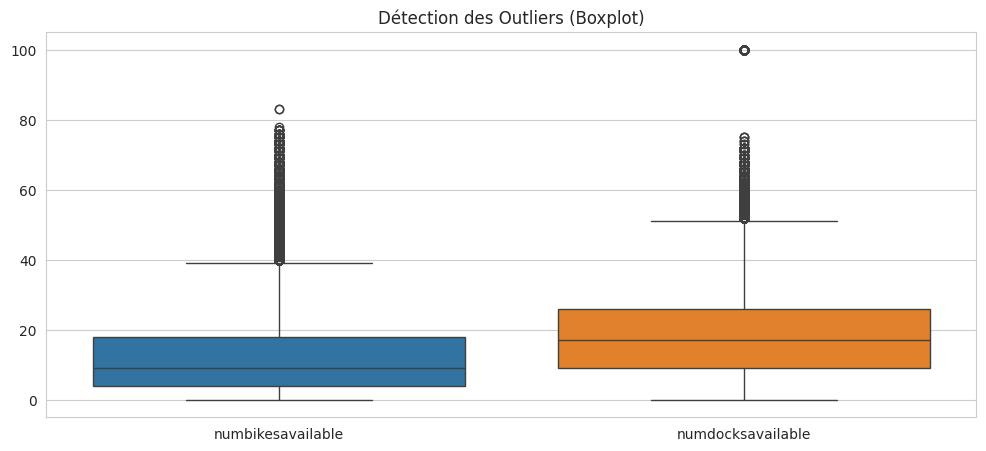

In [40]:
# --- DATA UNDERSTANDING ---

# Identification des cibles
targets = ['numbikesavailable', 'numdocksavailable']

# Analyse des valeurs manquantes
missing = df.isnull().sum()
print("\n--- VALEURS MANQUANTES ---")
print(missing[missing > 0])

# Visualisation des Cibles (Histogrammes)
plt.figure(figsize=(12, 5))
for i, col in enumerate(targets):
    plt.subplot(1, 2, i+1)
    sns.histplot(df[col], bins=30, kde=True, color='teal' if i==0 else 'orange')
    plt.title(f'Distribution : {col}')
plt.tight_layout()
plt.show()

# Analyse des Outliers (Boxplot)
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[targets])
plt.title("Détection des Outliers (Boxplot)")
plt.show()


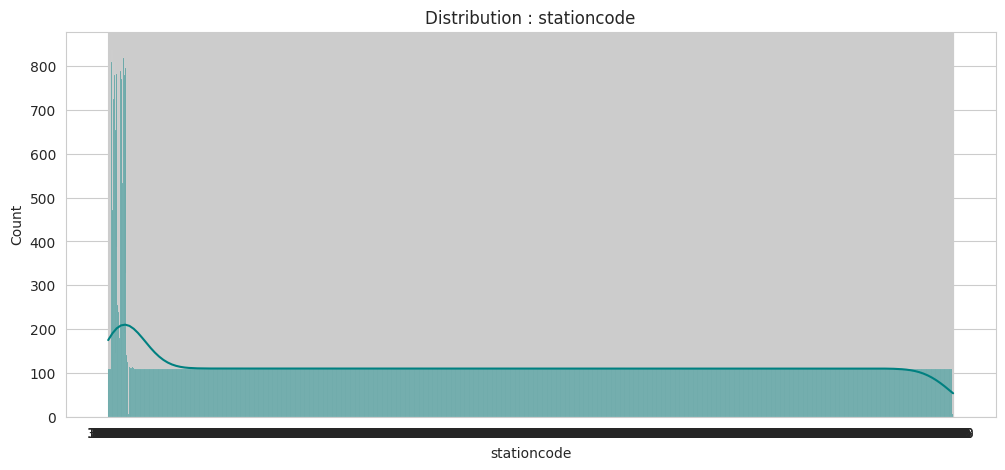

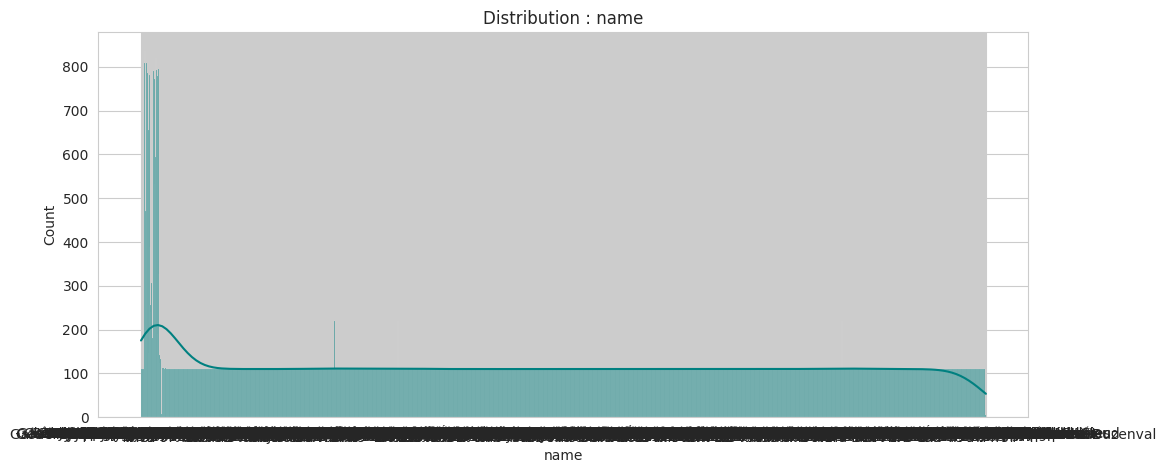

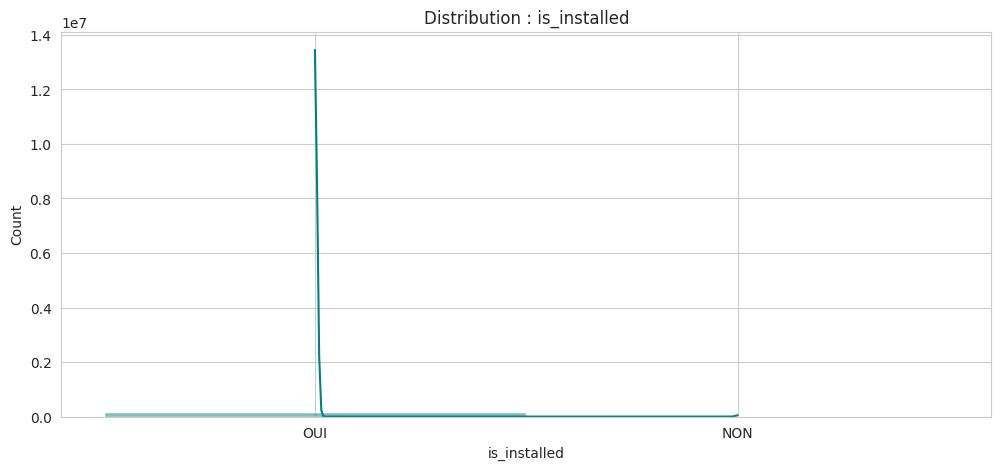

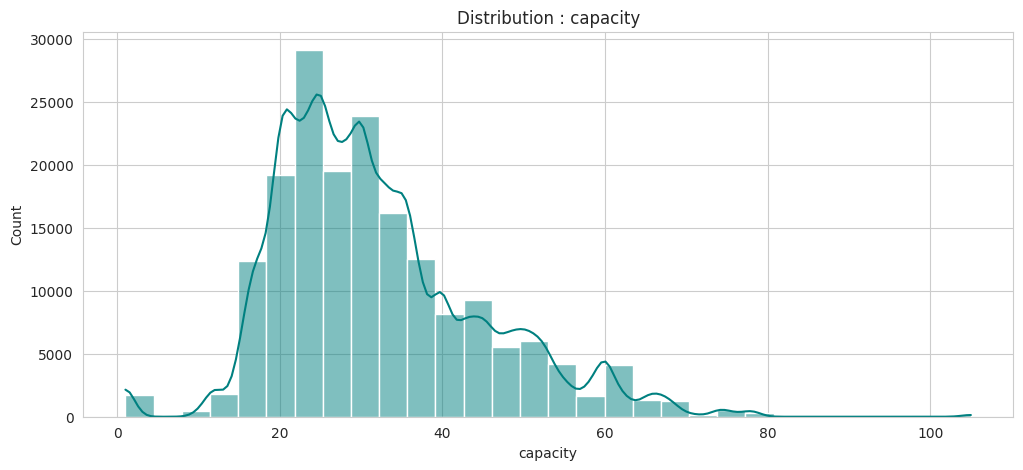

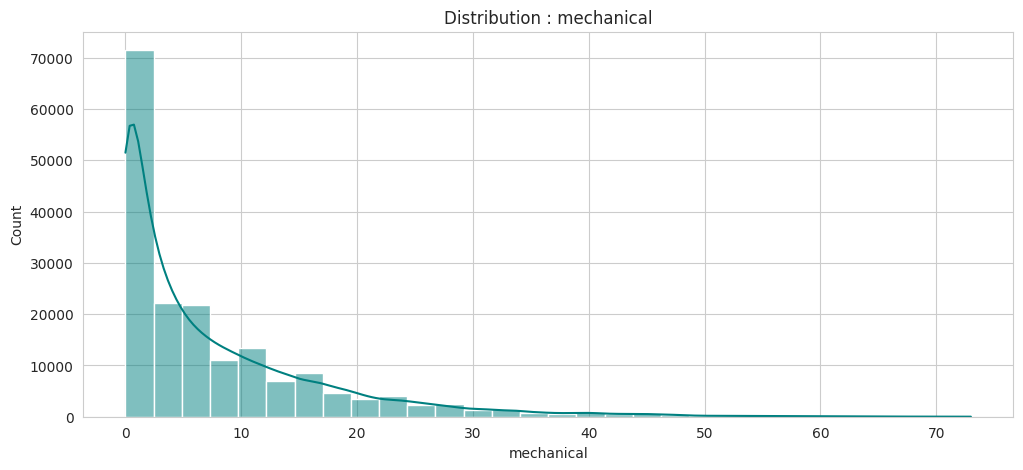

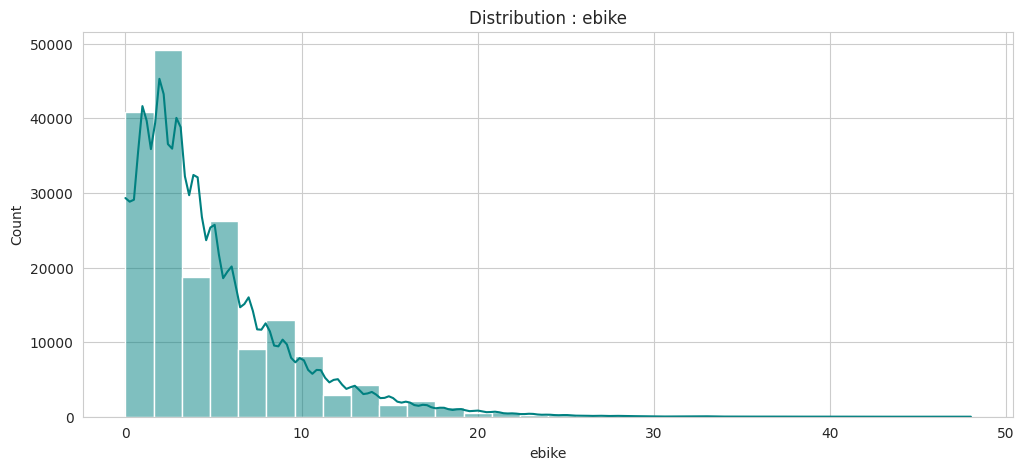

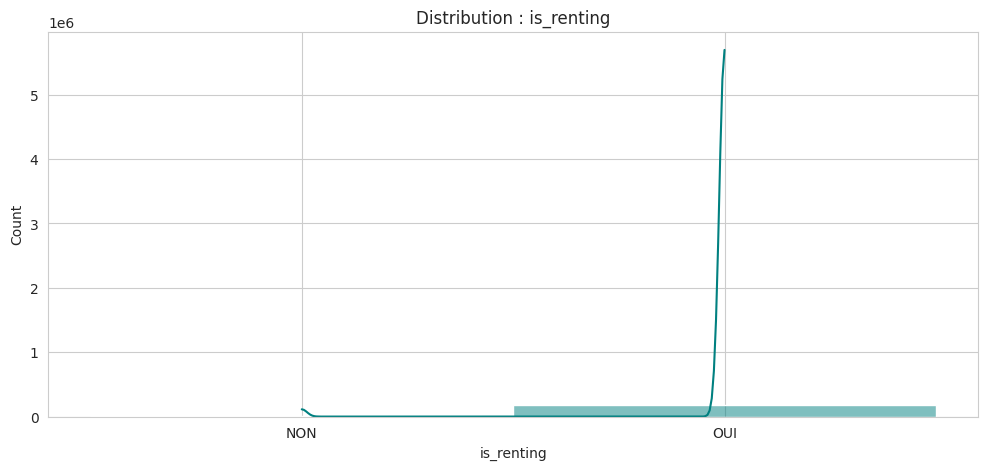

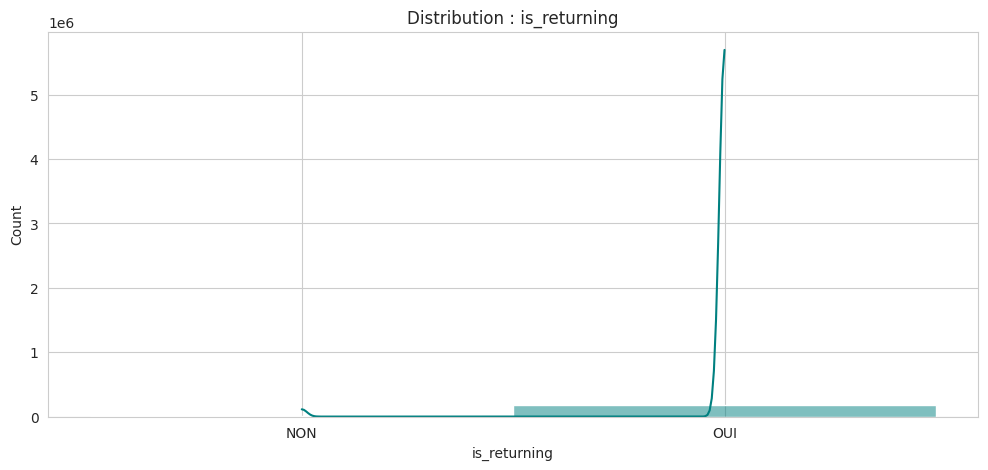

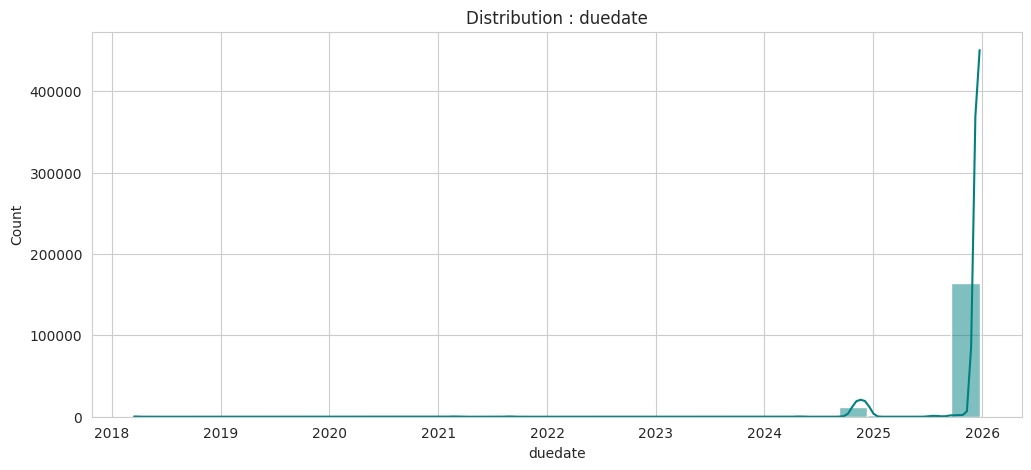

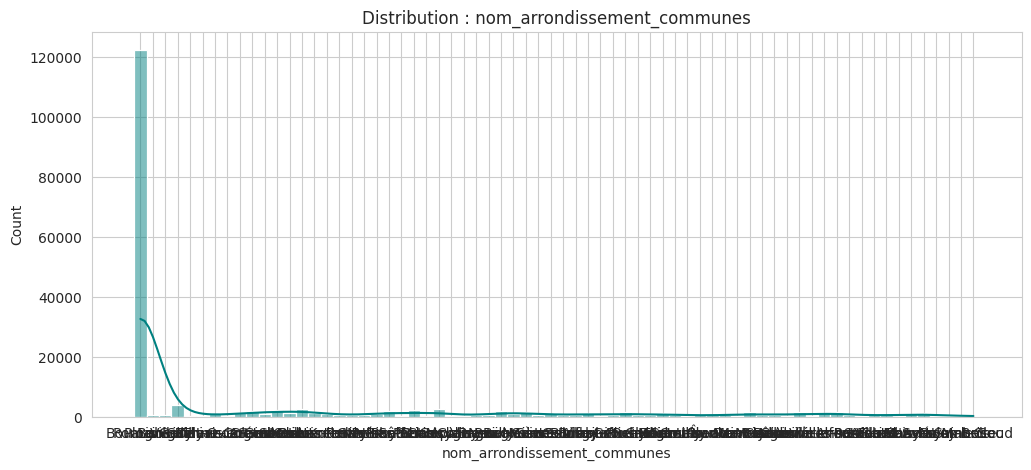

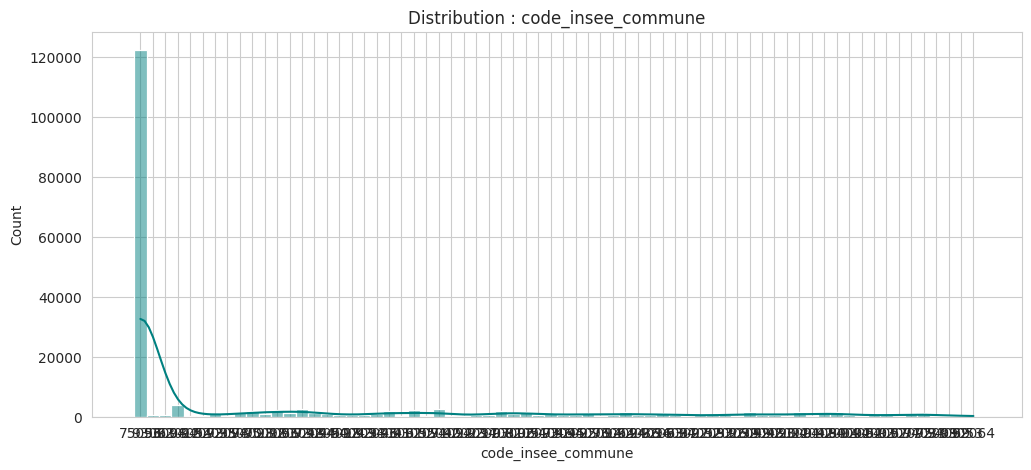

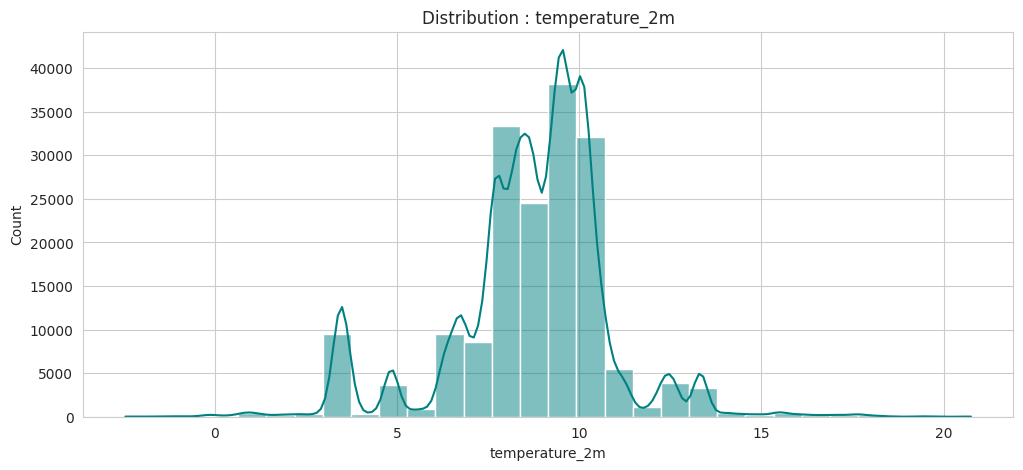

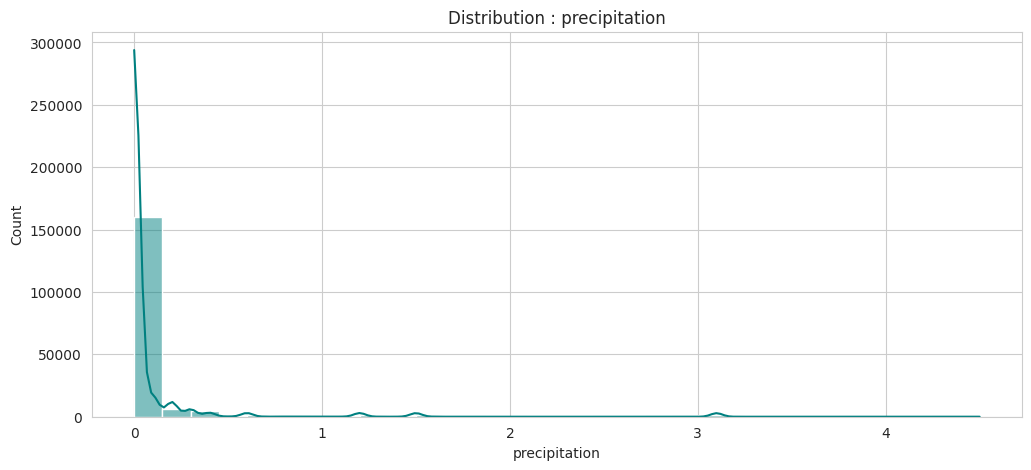

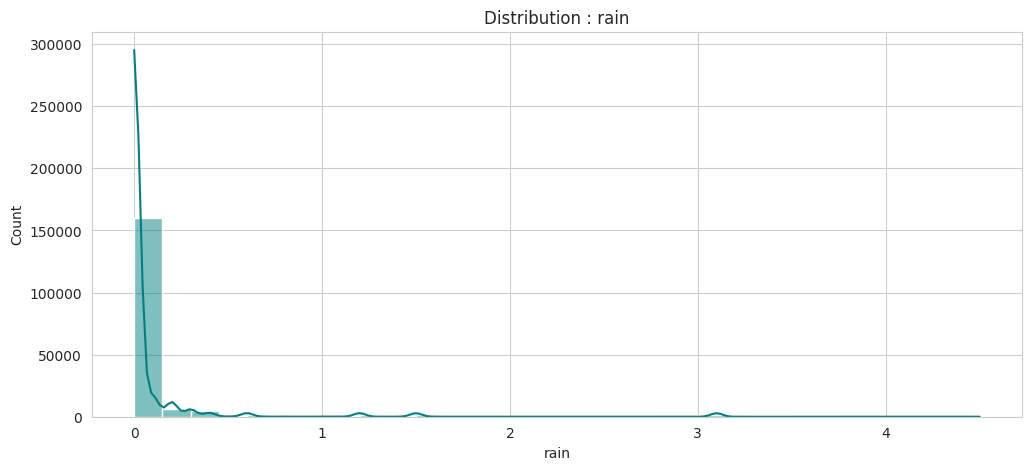

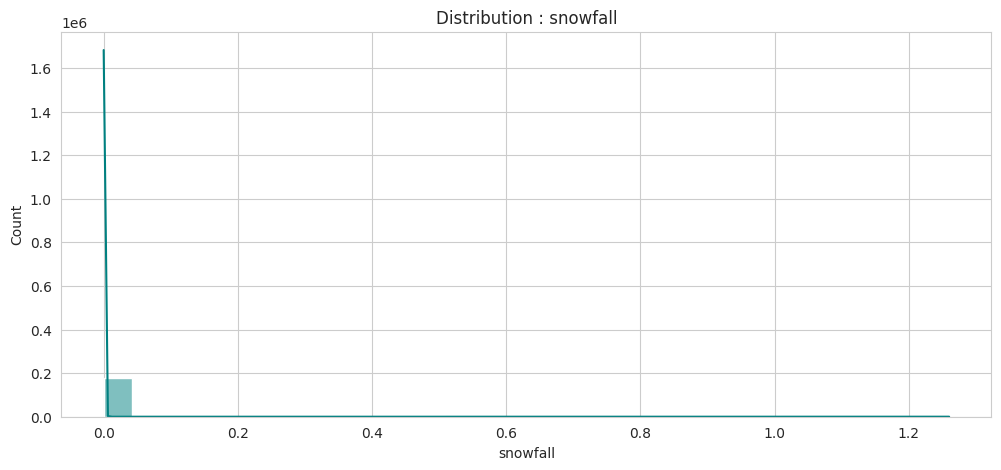

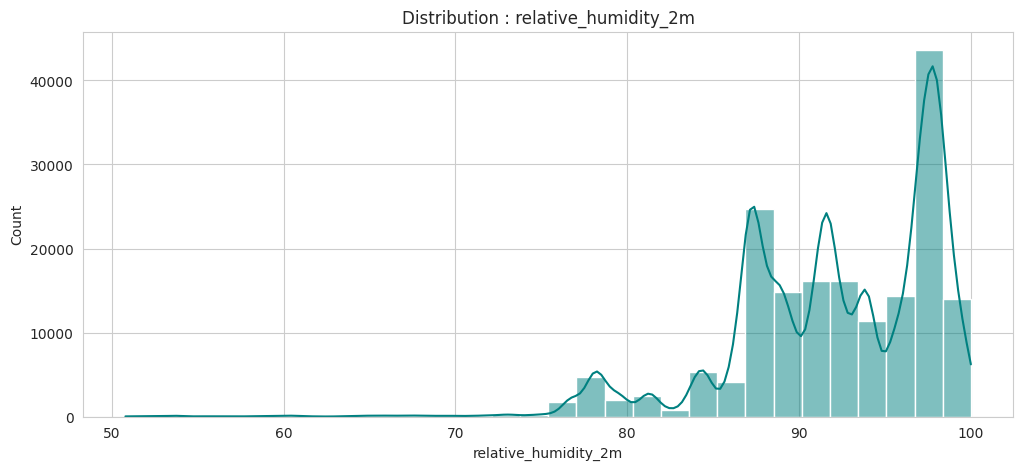

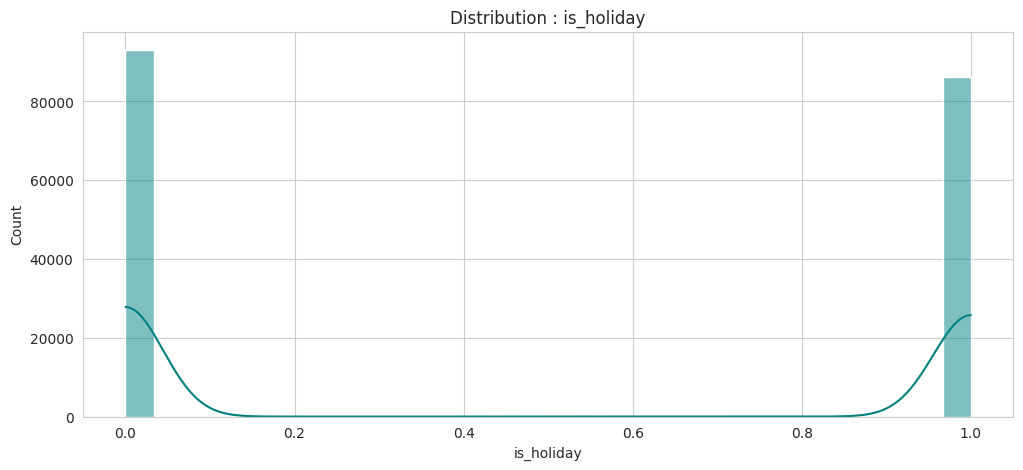

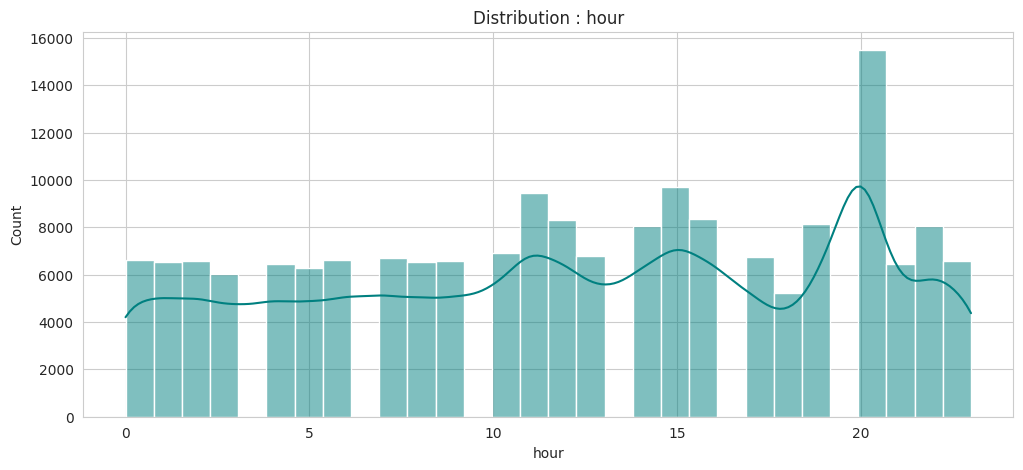

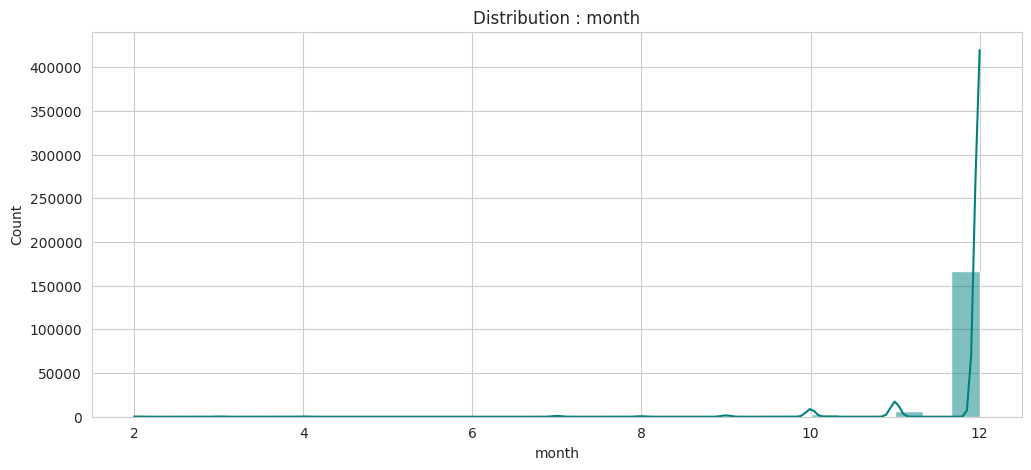

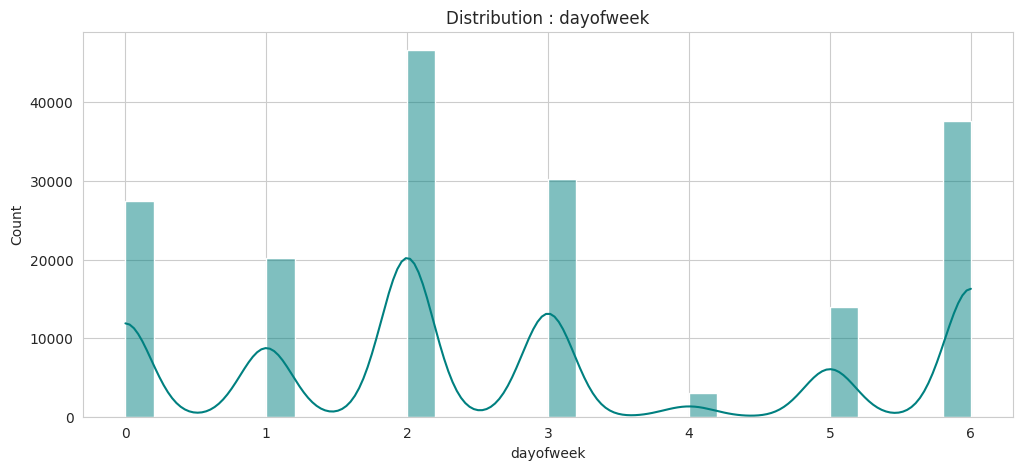

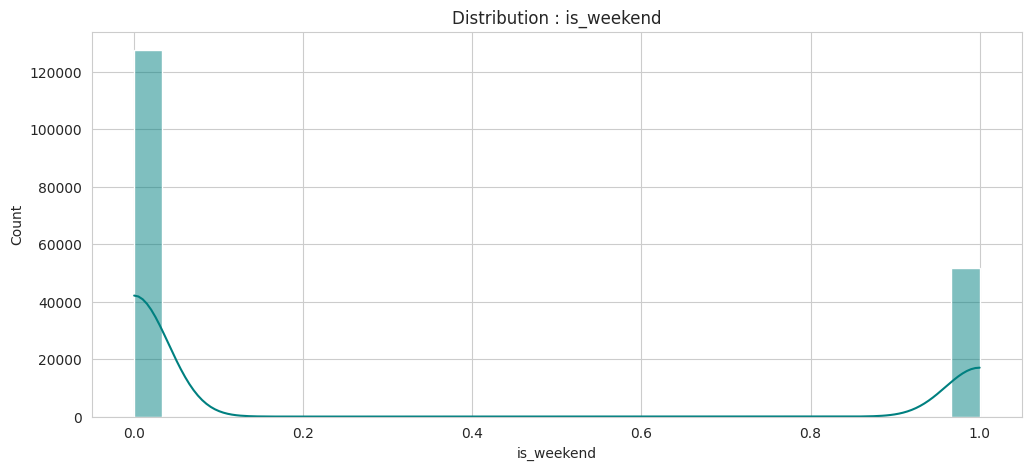

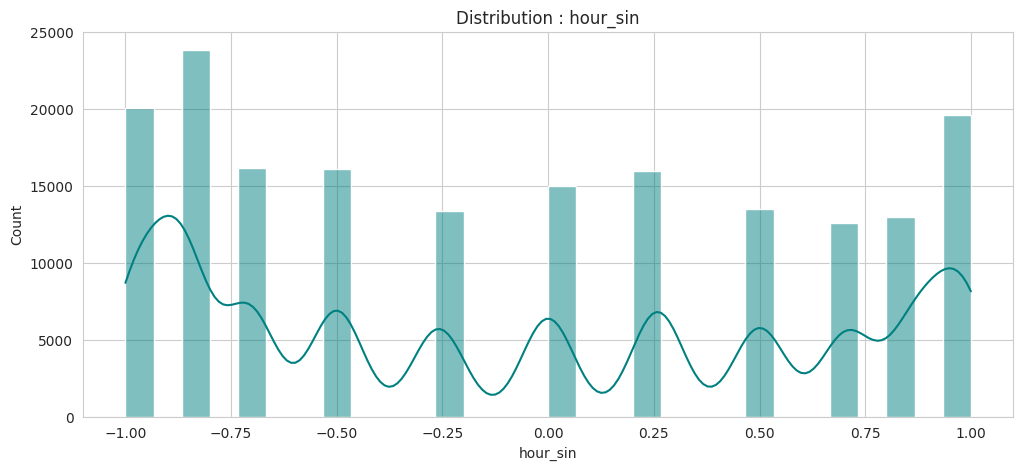

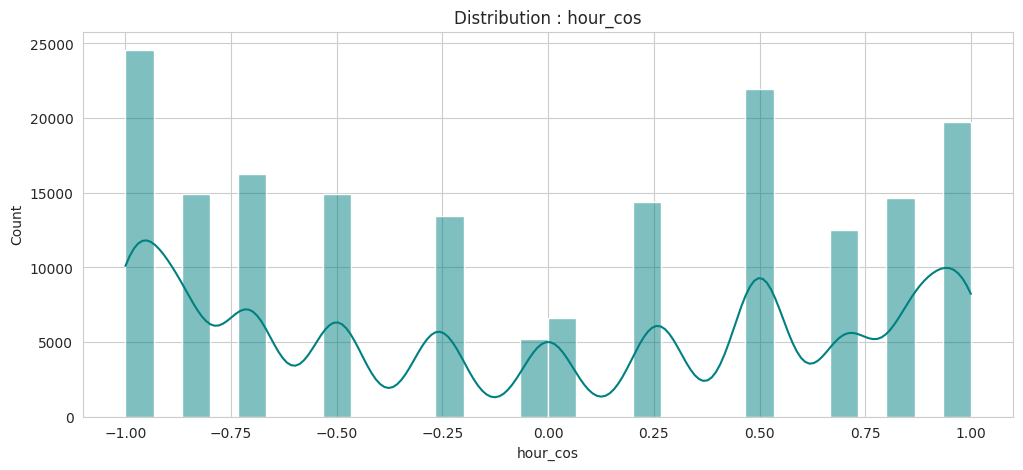

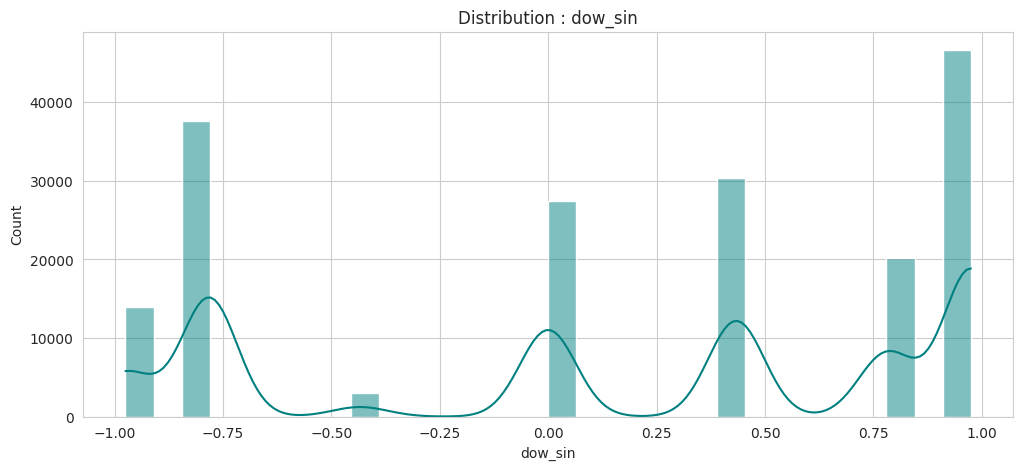

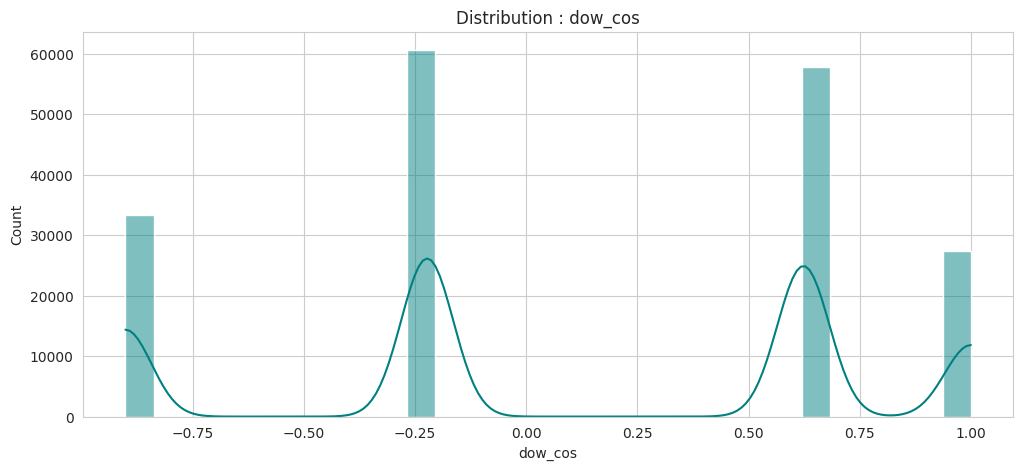

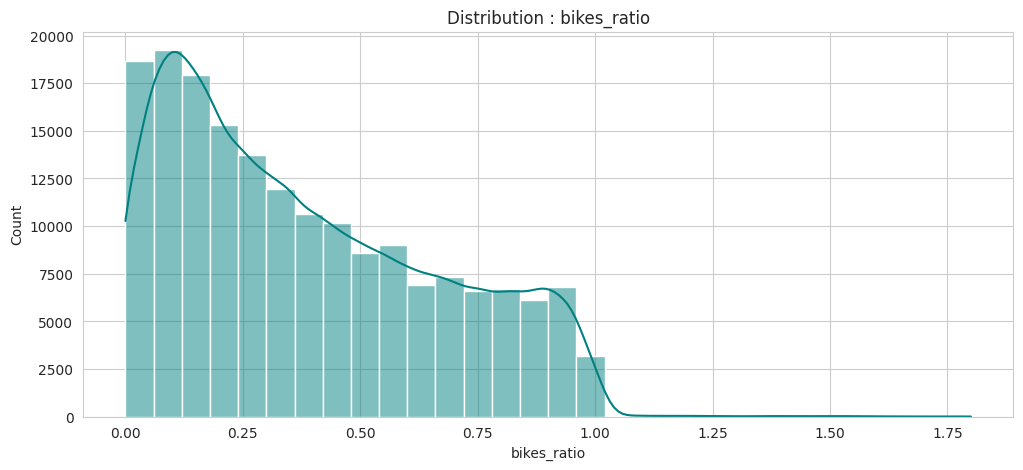

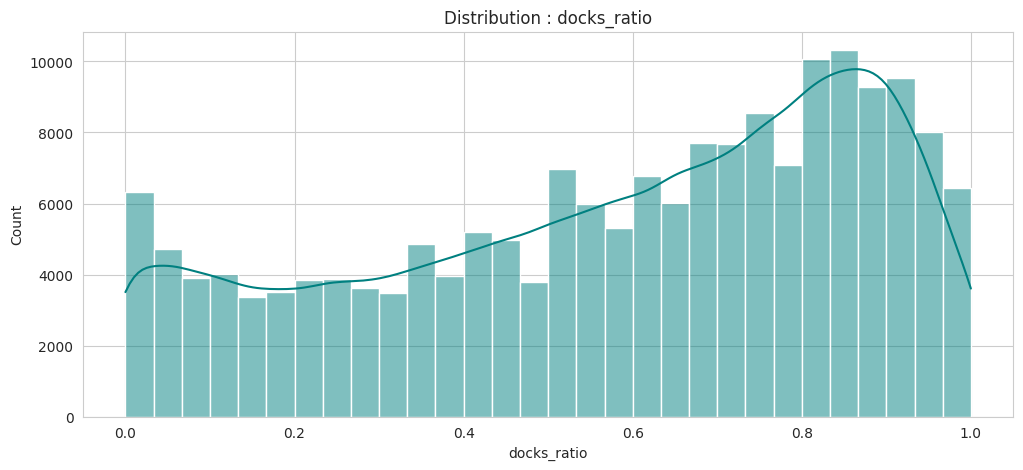

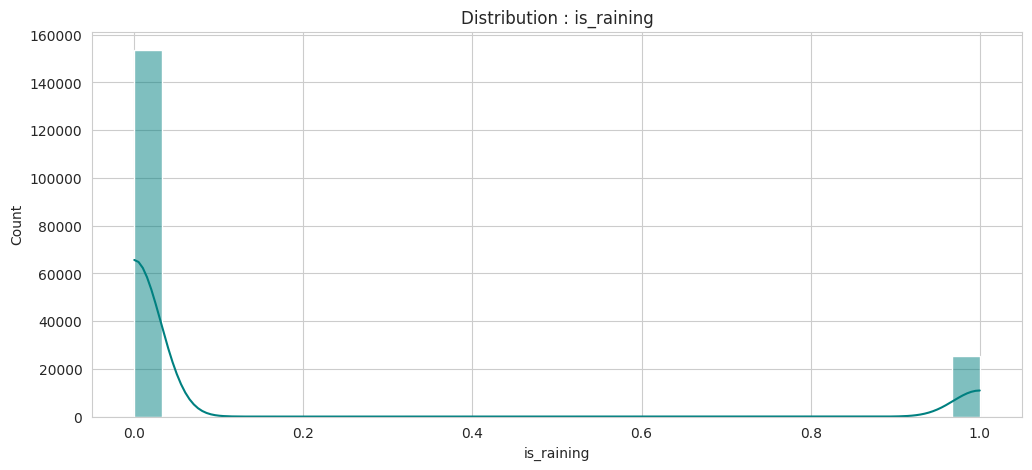

In [41]:
for i, col in enumerate(df.columns):
    if col in targets + ['coordonnees_geo']:
        continue
    plt.figure(figsize=(12, 5))
    sns.histplot(df[col], bins=30, kde=True, color='teal')
    plt.title(f'Distribution : {col}')


Text(0.5, 1.0, 'Correlation')

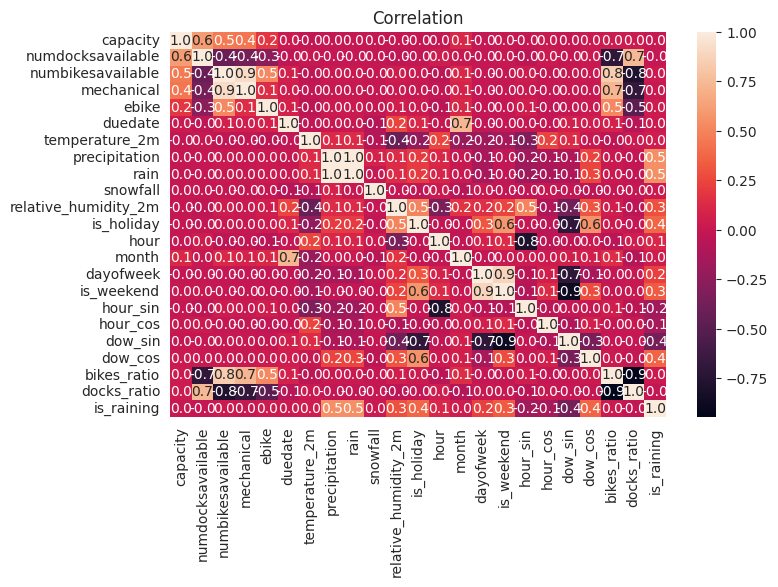

In [42]:
cat_values = df.select_dtypes(['object'])
num_values = df.drop(columns=cat_values.columns)
corr = num_values.corr()

plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, fmt=".1f")
plt.title("Correlation")

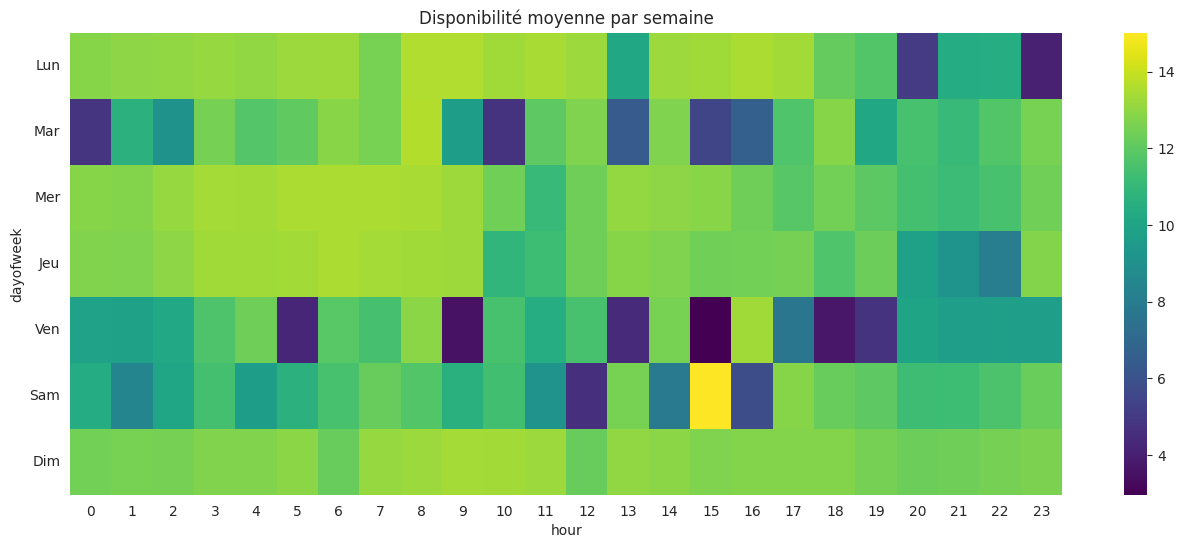

In [43]:
heatmap_data = df.pivot_table(index='dayofweek', columns='hour', values='numbikesavailable', aggfunc='mean')
plt.figure(figsize=(16, 6))
sns.heatmap(heatmap_data, cmap='viridis', annot=False)
plt.title("Disponibilité moyenne par semaine")
plt.yticks(ticks=np.arange(0.5, 7.5), labels=['Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim'], rotation=0)
plt.show()

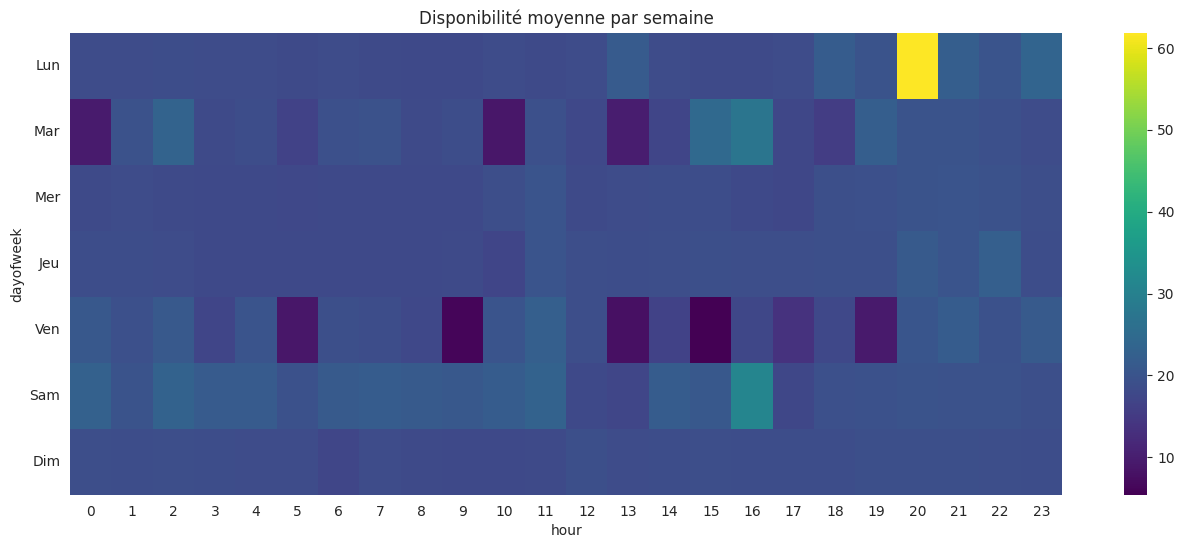

In [44]:
heatmap_data = df.pivot_table(index='dayofweek', columns='hour', values='numdocksavailable', aggfunc='mean')
plt.figure(figsize=(16, 6))
sns.heatmap(heatmap_data, cmap='viridis', annot=False)
plt.title("Disponibilité moyenne par semaine")
plt.yticks(ticks=np.arange(0.5, 7.5), labels=['Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim'], rotation=0)
plt.show()

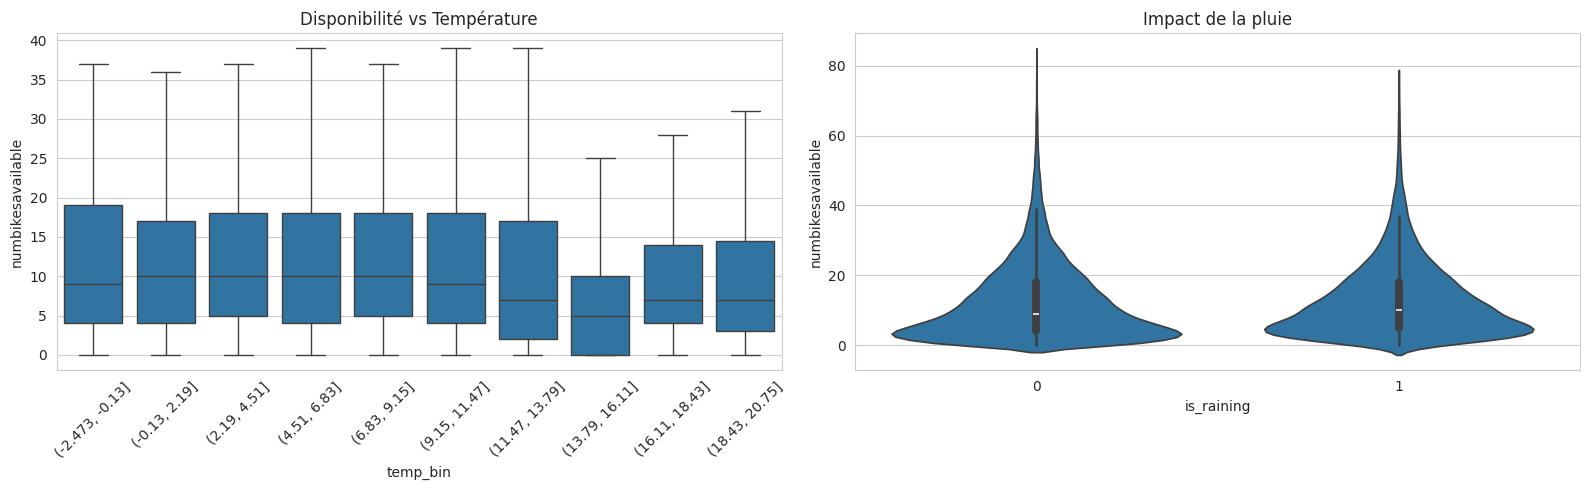

In [45]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
# Binning de la température pour voir des tendances
df['temp_bin'] = pd.cut(df['temperature_2m'], bins=10)
sns.boxplot(data=df, x='temp_bin', y='numbikesavailable', showfliers=False)
plt.xticks(rotation=45)
plt.title("Disponibilité vs Température")

plt.subplot(1, 2, 2)
sns.violinplot(data=df, x='is_raining', y='numbikesavailable')
plt.title("Impact de la pluie")

plt.tight_layout()

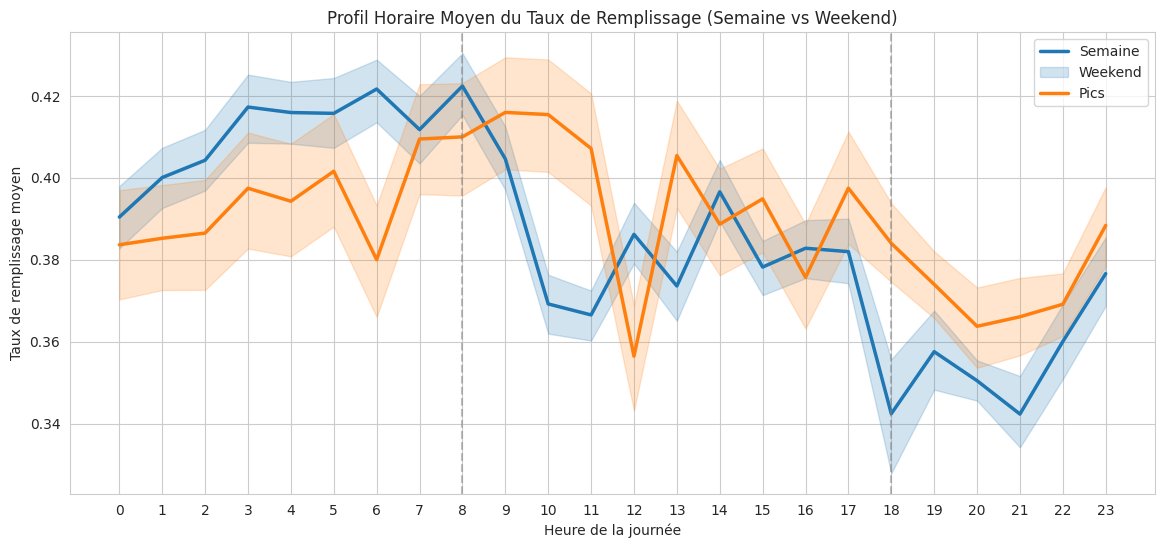

In [46]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=df, x='hour', y='bikes_ratio', hue='is_weekend',
             palette={False: '#1f77b4', True: '#ff7f0e'}, linewidth=2.5)

plt.title("Profil Horaire Moyen du Taux de Remplissage (Semaine vs Weekend)")
plt.ylabel("Taux de remplissage moyen")
plt.xlabel("Heure de la journée")
plt.xticks(range(0, 24))
plt.axvline(8, color='gray', linestyle='--', alpha=0.5, label='Pointe Matin (8h)')
plt.axvline(18, color='gray', linestyle='--', alpha=0.5, label='Pointe Soir (18h)')
plt.legend(['Semaine', 'Weekend', 'Pics'])
plt.show()

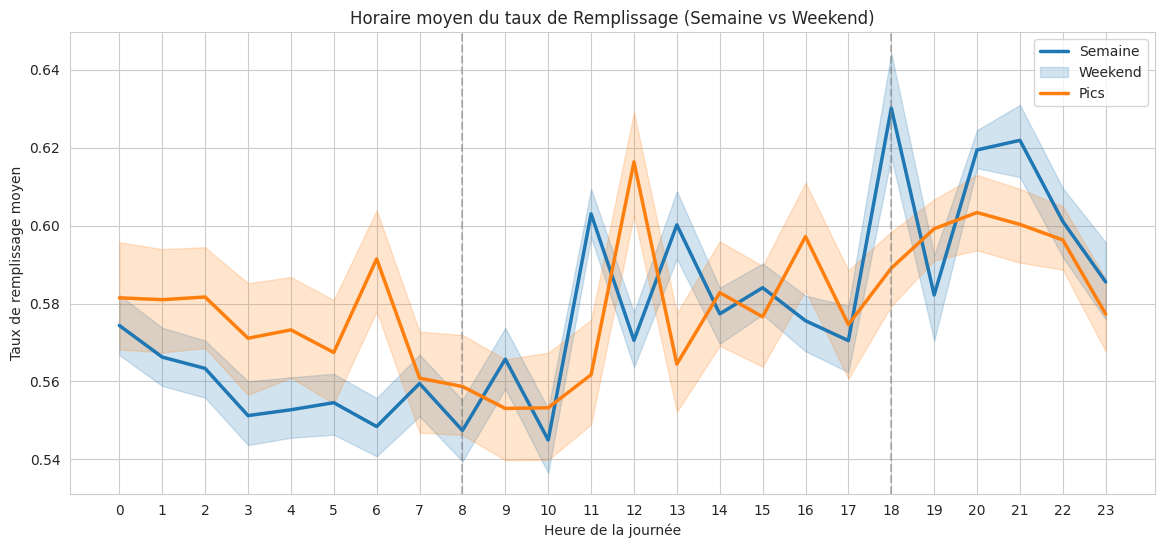

In [47]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=df, x='hour', y='docks_ratio', hue='is_weekend',
             palette={False: '#1f77b4', True: '#ff7f0e'}, linewidth=2.5)

plt.title("Horaire moyen du taux de Remplissage (Semaine vs Weekend)")
plt.ylabel("Taux de remplissage moyen")
plt.xlabel("Heure de la journée")
plt.xticks(range(0, 24))
plt.axvline(8, color='gray', linestyle='--', alpha=0.5, label='Pointe Matin (8h)')
plt.axvline(18, color='gray', linestyle='--', alpha=0.5, label='Pointe Soir (18h)')
plt.legend(['Semaine', 'Weekend', 'Pics'])
plt.show()